## 1.Introduction ##
I work for a market research company and every day we deal with thousand of files in all formats and structures. One of the multiple things we check is if a file delivered for a period of time is duplicated with another delivered file for previous period. This is currently done by running and comparing a statistic of the count of all records in the file, how many records are processed for the Unified format file and the amount of sales there are in the file. But this does not actually check if the content of the file is the same as a previously delivered one. In this project I will attempt to create a lightweight duplicate files checker while using mathematics to support the efficiency and correctness of the code.

## 2. Main Problem and Solution ##
Checking the statistics to find duplicated files works most of the time. It is improbable for two files, where both have records count in the thousands, to have the exact same statistic. But small files will fly under the radar easily. Retailers who specialize in a limited amount of high valued products can have the same sales and records in multiple periods and that needs to be checked manually for duplicity in case the contact person sent an old file for the current period.

The expected result of this project will be a lightweight process that can automatically detect duplicated files based on their contexts, not just the statistic. For this case I will use three Mathematical concepts:
* Jaccard index (Similarity theory)
* MinHashing (Probability theory)
* LSH banding (Optimization and S-curve)

## Set Similarity ##
Comparing two sets of documents can be done easily, but it is also time-tasking. Meaning that for each given document (*N*), comparing all the possible pairs will take roughly $O(N^2)$:

$$ \frac{N!}{2!(N-2)!} \sim N^2/2 \sim O(N^2) $$

So we will approximate the computation of this similarity using the hashing function Local-Sensitive Hashing (LSH), which will allow to focus on pairs that are likely to be similar without looking at all the pairs. These functions contain a property that pairs that are more similar tend to be on the same bucket defined by the hash functions.

First we need to define a metric that will help us find the similarity of the pairs, for which we will use the Jaccard index.

## Jaccard index (Similarity theory) ##

Jaccard index is a metric defined as the similarity of sets in relation to the size of their intersection:

![Jaccard.png](Assets/Jaccard.png)

Mathematically, if we are given two sets $A$ and $B$, the Jaccard similarity which we denote as $SIM(A, B)$ is:
$$SIM(A, B) = \frac{|A \cap B|}{|A \cup B|}$$

In order to get the sets needed to compare the documents we are going to use Shingling.

## Shingling ##

Shingling is a set of unique shingles or n-grams composed of contiguous subsequences of tokens within a document. Using shingling we can find similarity between documents even if the records appear in a different order. In order to apply shingling we will enumerate all the $k$-shingles of a document. $k$ refers to any substring with length $k$ found in the document. For this project, since it is intended for larger file processing in mind, we are going to be using one word for each shingle as a base.To further preserve the context of the files, for testing we will be using bigrams ($k = 2$) or simply put, each shingle set will be composed of two words separated by a blank space. For larger files, to preserve resources $k$ can be switched to 5 or 6.
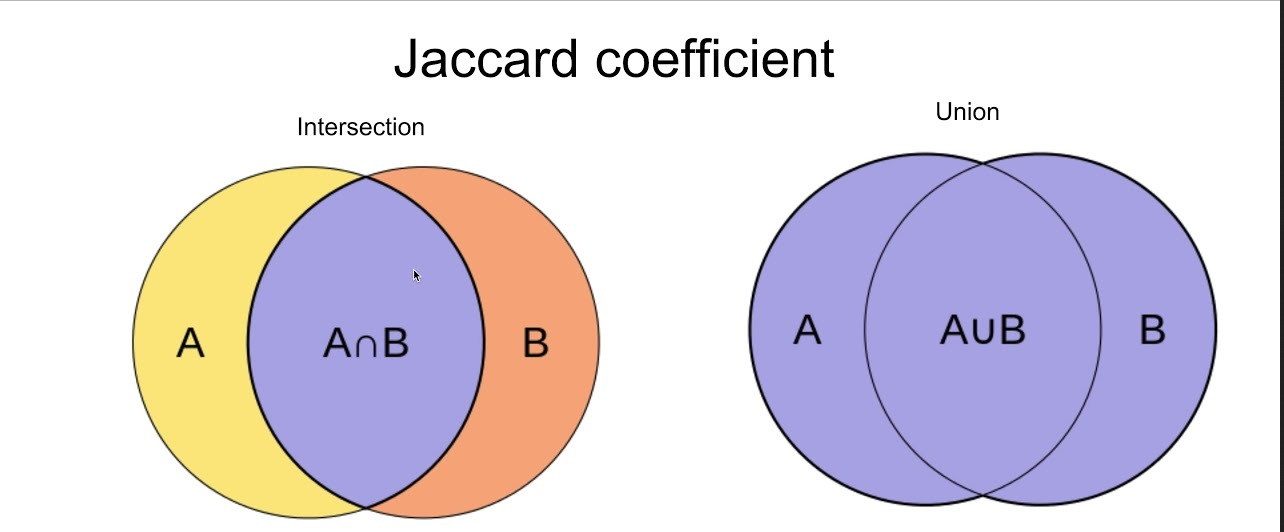
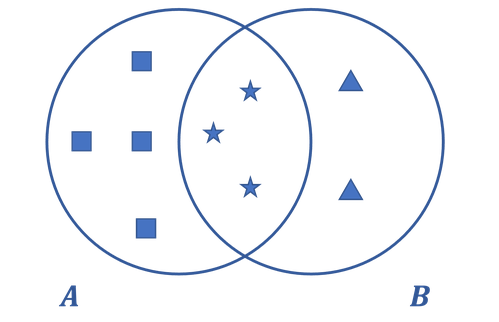
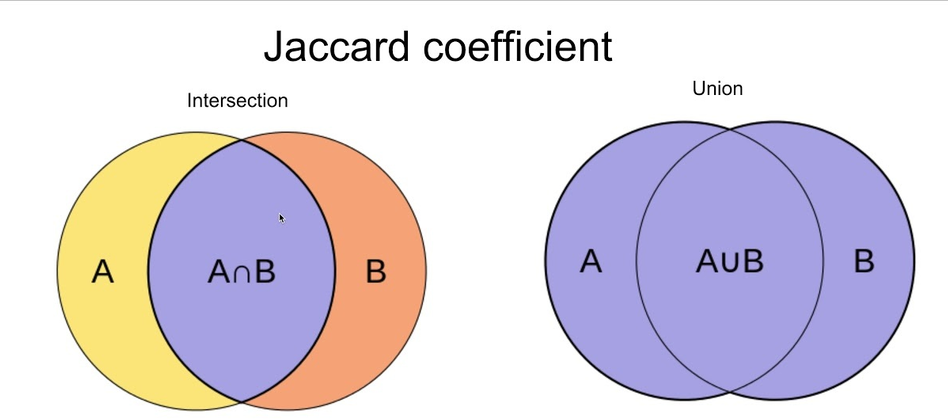